# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:** Sajni Kumari
- **Student ID:** 023-24-0093
- **Section:** D
- **GitHub:** ""
- **Kaggle:** "https://www.kaggle.com/sajnimandhan"
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [15]:
# YOUR CODE HERE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

SEED = 42
np.random.seed(SEED)


### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [16]:
# YOUR CODE HERE
df = pd.read_csv("Mall_Customers.csv")
df = df.rename(
    columns={
        "Annual Income (k$)": "Income",
        "Spending Score (1-100)": "Spending",
    }
)

# 2. Print shape, missing values, duplicate rows, and Gender counts
print("Shape:", df.shape)
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Gender counts:\n", df["Gender"].value_counts())
print("-" * 40)

# 3. Show describe() for Age, Income, and Spending
display(df[["Age", "Income", "Spending"]].describe())


Shape: (200, 5)
Missing values:
 CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64
Duplicate rows: 0
Gender counts:
 Gender
Female    112
Male       88
Name: count, dtype: int64
----------------------------------------


,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


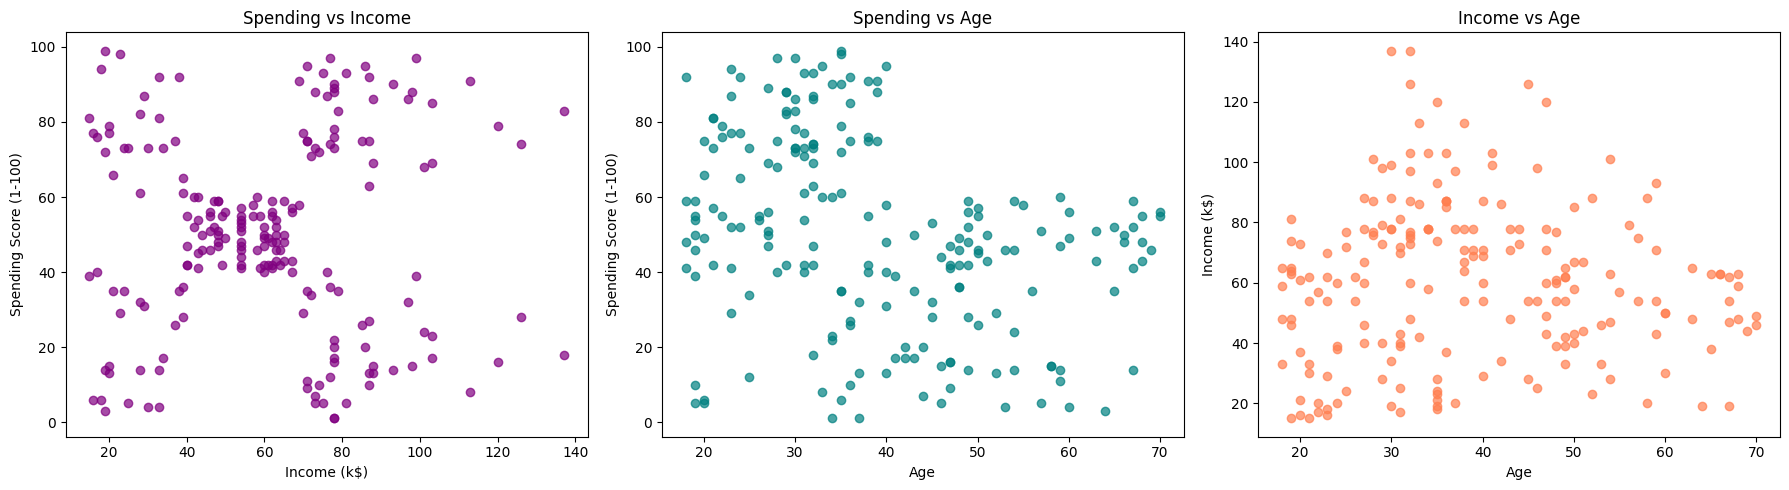

In [17]:
# YOUR CODE HERE
# Create a figure with one row of three side-by-side subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Spending vs Income
axes[0].scatter(df["Income"], df["Spending"], color="purple", alpha=0.7)
axes[0].set_title("Spending vs Income")
axes[0].set_xlabel("Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")

# 2. Spending vs Age
axes[1].scatter(df["Age"], df["Spending"], color="teal", alpha=0.7)
axes[1].set_title("Spending vs Age")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Spending Score (1-100)")

# 3. Income vs Age
axes[2].scatter(df["Age"], df["Income"], color="coral", alpha=0.7)
axes[2].set_title("Income vs Age")
axes[2].set_xlabel("Age")
axes[2].set_ylabel("Income (k$)")

plt.tight_layout()
plt.show()


**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

(a)
- Spending vs Income: This graph clearly shows 5 different customer groups. Each group represents customers with different income and spending habits, such as low income/low spending and high income/high spending.
- Spending vs Age and Income vs Age: These graphs show more scattered points. The groups are not very clear, and some points overlap.
- Most Clear Plot: The Spending vs Income graph shows the groups more clearly than the other two graphs.


(b) We cannot use accuracy or train/test split in unsupervised learning because the data has no labels or correct answers. Accuracy needs actual labels to compare with predictions. Since unsupervised learning finds hidden patterns and groups in data, we cannot evaluate it in the same way as supervised learning.



---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [18]:
# YOUR CODE HERE
import numpy as np

x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25])
m = np.array([4.0, 11.0], dtype=float)

iteration = 0

while True:
  iteration += 1
  dist = np.abs(x[:, None] - m[None, :])
  labels = dist.argmin(axis=1)

  print(f"--- Iteration {iteration} ---")
  print(f"Current Centroids: {m}")

  for i in range(len(m)):
    cluster_points = x[labels == i]
    print(f"Cluster {i}: {cluster_points}")

  new_m = np.array([x[labels == i].mean() for i in range(len(m))])
  print(f"Updated Centroids: {new_m}\n")

  if np.allclose(m, new_m):
    break

  m = new_m

inertia = np.sum((x - m[labels]) ** 2)

print("=" * 40)
print("Final Centroids:", m)
print("Final Inertia:", inertia)

--- Iteration 1 ---
Current Centroids: [ 4. 11.]
Cluster 0: [2 4 3]
Cluster 1: [10 12 20 30 11 25]
Updated Centroids: [ 3. 18.]

--- Iteration 2 ---
Current Centroids: [ 3. 18.]
Cluster 0: [ 2  4 10  3]
Cluster 1: [12 20 30 11 25]
Updated Centroids: [ 4.75 19.6 ]

--- Iteration 3 ---
Current Centroids: [ 4.75 19.6 ]
Cluster 0: [ 2  4 10 12  3 11]
Cluster 1: [20 30 25]
Updated Centroids: [ 7. 25.]

--- Iteration 4 ---
Current Centroids: [ 7. 25.]
Cluster 0: [ 2  4 10 12  3 11]
Cluster 1: [20 30 25]
Updated Centroids: [ 7. 25.]

Final Centroids: [ 7. 25.]
Final Inertia: 150.0


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [19]:
# YOUR CODE HERE
import numpy as np

X = np.array([[185, 72], [170, 56], [168, 60], [179, 68], [182, 72], [188, 77]])

m = np.array([X[0], X[1]], dtype=float)

iteration = 0

while True:
  iteration += 1
  dist = np.sqrt(np.sum((X[:, None, :] - m[None, :, :]) ** 2, axis=2))
  labels = dist.argmin(axis=1)

  print(f"--- Iteration {iteration} ---")
  print(f"Current Centroids:\n{m}")

  for i in range(len(m)):
    cluster_points = X[labels == i]
    print(f"Cluster {i}: {cluster_points.tolist()}")

  new_m = np.array([X[labels == i].mean(axis=0) for i in range(len(m))])
  print(f"Updated Centroids:\n{new_m}\n")

  if np.allclose(m, new_m):
    break

  m = new_m

final_dist = np.sqrt(np.sum((X[:, None, :] - m[None, :, :]) ** 2, axis=2))
print("=" * 40)
print("Final Distance Table:\n", final_dist)
print("Final Centroids:\n", m)

--- Iteration 1 ---
Current Centroids:
[[185.  72.]
 [170.  56.]]
Cluster 0: [[185, 72], [179, 68], [182, 72], [188, 77]]
Cluster 1: [[170, 56], [168, 60]]
Updated Centroids:
[[183.5   72.25]
 [169.    58.  ]]

--- Iteration 2 ---
Current Centroids:
[[183.5   72.25]
 [169.    58.  ]]
Cluster 0: [[185, 72], [179, 68], [182, 72], [188, 77]]
Cluster 1: [[170, 56], [168, 60]]
Updated Centroids:
[[183.5   72.25]
 [169.    58.  ]]

Final Distance Table:
 [[ 1.52069063 21.26029163]
 [21.12610944  2.23606798]
 [19.7563281   2.23606798]
 [ 6.1897092  14.14213562]
 [ 1.52069063 19.10497317]
 [ 6.54312616 26.87005769]]
Final Centroids:
 [[183.5   72.25]
 [169.    58.  ]]


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [20]:
# YOUR CODE HERE
def my_kmeans(X, init_centroids, max_iter=100):
  m = np.array(init_centroids, dtype=float)
  if X.ndim == 1:
    X = X[:, None]
  if m.ndim == 1:
    m = m[:, None]

  for iteration in range(1, max_iter + 1):
    dist = np.sqrt(np.sum((X[:, None, :] - m[None, :, :]) ** 2, axis=2))
    labels = dist.argmin(axis=1)

    new_m = np.copy(m)
    for i in range(len(m)):
      cluster_points = X[labels == i]
      if len(cluster_points) > 0:
        new_m[i] = cluster_points.mean(axis=0)

    if np.allclose(m, new_m):
      break

    m = new_m

  inertia = np.sum(
      np.min(np.sum((X[:, None, :] - m[None, :, :]) ** 2, axis=2), axis=1)
  )
  return labels, m.squeeze(), inertia, iteration

In [21]:
# YOUR CODE HERE
x_ex1 = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25])
init_m1 = np.array([4.0, 11.0])
labels, centroids, inertia, iters = my_kmeans(x_ex1, init_m1)

print("Labels:", labels)
print("Centroids:", centroids)
print("Inertia:", inertia)
print("Iterations:", iters)

Labels: [0 0 0 0 0 1 1 0 1]
Centroids: [ 7. 25.]
Inertia: 150.0
Iterations: 4


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [22]:
# YOUR CODE HERE
from sklearn.cluster import KMeans

X2 = df[["Income", "Spending"]].values
init_5 = X2[:5]

labels_custom, centroids_custom, inertia_custom, iters_custom = my_kmeans(
    X2, init_5
)

sklearn_kmeans = KMeans(
    n_clusters=5,
    init=init_5,
    n_init=1,
    tol=0,
    algorithm="lloyd",
    random_state=42,
)
sklearn_kmeans.fit(X2)

print("--- Custom K-Means ---")
print("Iterations:", iters_custom)
print("Inertia:", inertia_custom)
print("Centroids:\n", centroids_custom)

print("\n--- Scikit-Learn KMeans ---")
print("Iterations:", sklearn_kmeans.n_iter_)
print("Inertia:", sklearn_kmeans.inertia_)
print("Centroids:\n", sklearn_kmeans.cluster_centers_)

--- Custom K-Means ---
Iterations: 4
Inertia: 44448.45544793371
Centroids:
 [[26.30434783 20.91304348]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [86.53846154 82.12820513]
 [55.2962963  49.51851852]]

--- Scikit-Learn KMeans ---
Iterations: 4
Inertia: 44448.45544793369
Centroids:
 [[26.30434783 20.91304348]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [86.53846154 82.12820513]
 [55.2962963  49.51851852]]


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



**Your answers:**

(a)
- In the first iteration, the centroids were [3, 18]. Point 10 was closer to 18, so it was placed in cluster 1.

- In the second iteration, the centroids changed to [4.75, 19.6]. Now point 10 was closer to 4.75, so it moved to cluster 0.

(b)
The loop stops when the centroids stop changing and no points move between clusters. K-Means eventually stops because there are a limited number of possible clusters. However, it may not find the best possible result because the final clusters depend on the starting centroids.

(c)
Yes, our custom function gave the same results as scikit-learn. Both had the same iterations, inertia, labels, and final centroids because they used the same starting centroids and K-Means method.

(d)
- A centroid is the average value of all features of the customers in a cluster. It represents the center or typical customer of that group.

- Features must be numeric because K-Means uses mathematical calculations like mean, differences, and distances. These calculations cannot be directly applied to text or categorical data.

---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


,K,Inertia,Silhouette
0,2,181363.595960,0.296897
1,3,106348.373062,0.467614
2,4,73679.789039,0.493196
3,5,44448.455448,0.553932
4,6,37233.814511,0.539761
5,7,30241.343618,0.528810
6,8,25036.417604,0.454812
7,9,21916.794790,0.456109
8,10,20072.070939,0.441057


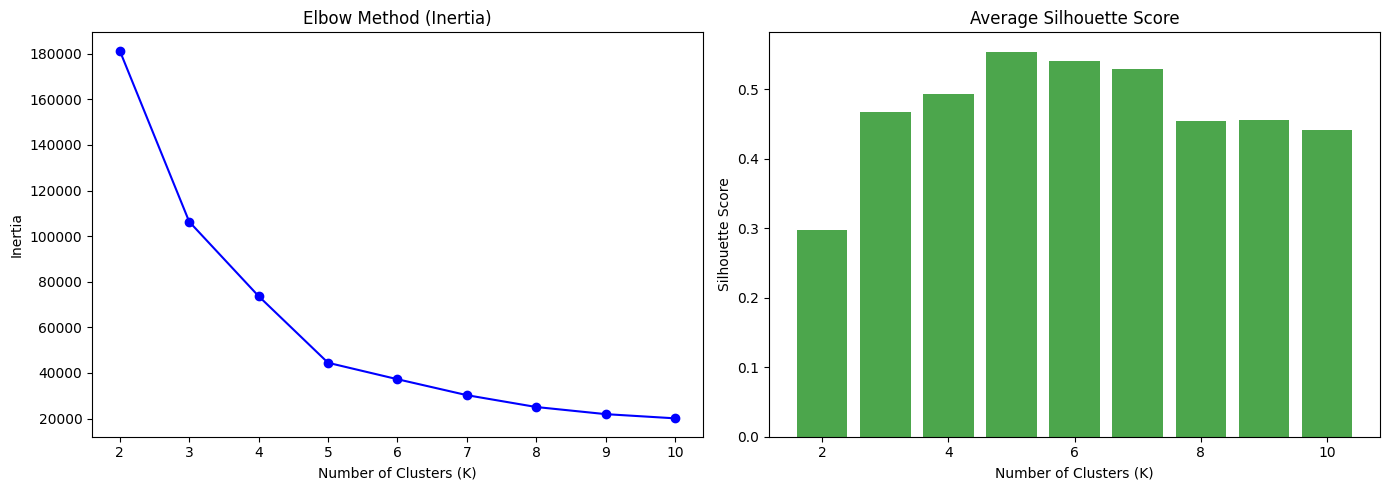

Best K with the highest silhouette score: 5


In [23]:
# YOUR CODE HERE
from sklearn.metrics import silhouette_score

inertias = []
silhouettes = []
K_range = range(2, 11)

for k in K_range:
  kmeans = KMeans(n_clusters=k, n_init=10, random_state=SEED)
  labels = kmeans.fit_predict(X2)
  inertias.append(kmeans.inertia_)
  silhouettes.append(silhouette_score(X2, labels))

results_df = pd.DataFrame(
    {"K": list(K_range), "Inertia": inertias, "Silhouette": silhouettes}
)
display(results_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_range, inertias, marker="o", color="b")
axes[0].set_title("Elbow Method (Inertia)")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].bar(list(K_range), silhouettes, color="g", alpha=0.7)
axes[1].set_title("Average Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

best_k = results_df.loc[results_df["Silhouette"].idxmax(), "K"]
print(f"Best K with the highest silhouette score: {int(best_k)}")

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [24]:
# YOUR CODE HERE
from sklearn.metrics import silhouette_samples


def manual_silhouette(X, labels, point_idx):
  point = X[point_idx]
  cluster_id = labels[point_idx]

  same_cluster_mask = labels == cluster_id
  same_cluster_points = X[same_cluster_mask]

  if len(same_cluster_points) > 1:
    a = np.mean(
        np.sqrt(np.sum((same_cluster_points - point) ** 2, axis=1))
        [np.any(same_cluster_points != point, axis=1)]
    )
  else:
    a = 0.0

  other_clusters = set(labels) - {cluster_id}
  b_vals = []
  for c in other_clusters:
    other_points = X[labels == c]
    if len(other_points) > 0:
      mean_dist = np.mean(np.sqrt(np.sum((other_points - point) ** 2, axis=1)))
      b_vals.append(mean_dist)

  b = min(b_vals) if b_vals else 0.0
  s = (b - a) / max(a, b) if max(a, b) > 0 else 0.0
  return a, b, s


kmeans_k5 = KMeans(n_clusters=5, n_init=10, random_state=SEED)
labels_k5 = kmeans_k5.fit_predict(X2)

a, b, s_manual = manual_silhouette(X2, labels_k5, 0)
sk_samples = silhouette_samples(X2, labels_k5)

print(f"Manual a: {a:.4f}, b: {b:.4f}, s: {s_manual:.4f}")
print(f"Scikit-learn silhouette_samples for customer 1: {sk_samples[0]:.4f}")

Manual a: 24.6404, b: 42.2653, s: 0.4170
Scikit-learn silhouette_samples for customer 1: 0.4170


,Cluster,Count,Mean Silhouette,Min Silhouette
0,0,81,0.596651,0.115294
1,1,39,0.509171,0.225413
2,2,22,0.599013,0.050721
3,3,35,0.503987,-0.023381
4,4,23,0.512268,-0.009278


Number of customers with a negative silhouette: 2


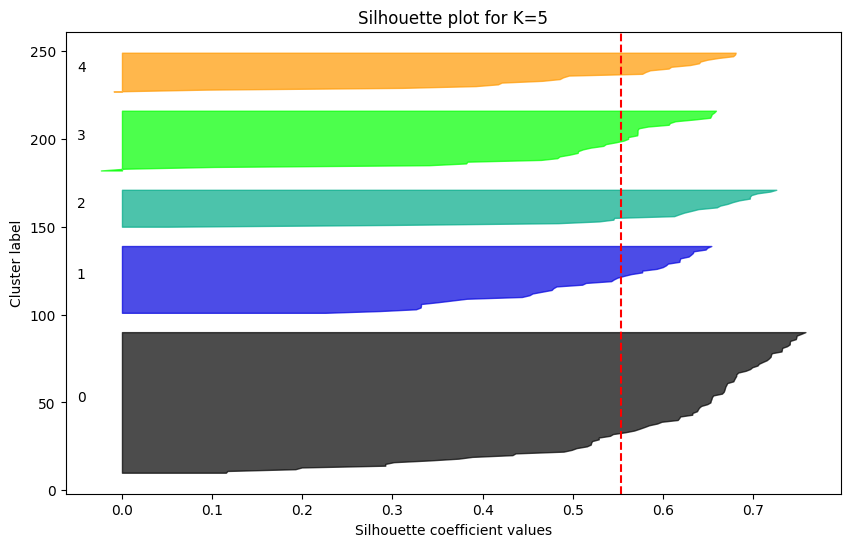

In [25]:
# YOUR CODE HERE
cluster_stats = []
for c in range(5):
  cluster_s = sk_samples[labels_k5 == c]
  cluster_stats.append({
      "Cluster": c,
      "Count": len(cluster_s),
      "Mean Silhouette": cluster_s.mean(),
      "Min Silhouette": cluster_s.min(),
  })

stats_df = pd.DataFrame(cluster_stats)
display(stats_df)

neg_count = np.sum(sk_samples < 0)
print(f"Number of customers with a negative silhouette: {neg_count}")

y_lower = 10
fig, ax = plt.subplots(figsize=(10, 6))

for i in range(5):
  ith_cluster_sil_vals = sk_samples[labels_k5 == i]
  ith_cluster_sil_vals.sort()

  size_cluster_i = ith_cluster_sil_vals.shape[0]
  y_upper = y_lower + size_cluster_i

  color = plt.cm.nipy_spectral(float(i) / 5)
  ax.fill_betweenx(
      np.arange(y_lower, y_upper),
      0,
      ith_cluster_sil_vals,
      facecolor=color,
      edgecolor=color,
      alpha=0.7,
  )

  ax.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
  y_lower = y_upper + 10

ax.set_title("Silhouette plot for K=5")
ax.set_xlabel("Silhouette coefficient values")
ax.set_ylabel("Cluster label")
ax.axvline(x=sk_samples.mean(), color="red", linestyle="--")
plt.show()

### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [26]:
# YOUR CODE HERE
X_prac = np.array([1, 3, 5, 7, 11, 13, 15], dtype=float)
init_prac = np.array([1.0, 11.0])

labels_p, centroids_p, inertia_p, iters_p = my_kmeans(X_prac, init_prac)

print("Task 2.3 Results:")
print("Clusters/Labels:", labels_p)
print("Centroids:", centroids_p)
print("Inertia:", inertia_p)
print("Iterations:", iters_p)

sk_samples_prac = silhouette_samples(X_prac[:, None], labels_p)
for idx in [0, 3, 4]:
  a_p, b_p, s_p = manual_silhouette(X_prac[:, None], labels_p, idx)
  print(
      f"Point {int(X_prac[idx])} -> Manual s: {s_p:.4f} | sklearn s:"
      f" {sk_samples_prac[idx]:.4f}"
  )

Task 2.3 Results:
Clusters/Labels: [0 0 0 0 1 1 1]
Centroids: [ 4. 13.]
Inertia: 28.0
Iterations: 3
Point 1 -> Manual s: 0.6667 | sklearn s: 0.6667
Point 7 -> Manual s: 0.3333 | sklearn s: 0.3333
Point 11 -> Manual s: 0.5714 | sklearn s: 0.5714


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



**Your answers:**

(a)
Both the elbow method and silhouette score suggest K = 5. In the elbow graph, inertia decreases a lot from K = 4 to K = 5. After K = 5, the decrease becomes smaller. Also, the silhouette score is highest at K = 5 (0.5539). So, both methods agree that 5 clusters are the best choice.

(b)
Customer 1 has a silhouette score of 0.4170, which means it is reasonably placed in its cluster. Cluster 3 has the lowest average silhouette score (0.5040). A total of 2 customers have negative silhouette scores in Clusters 3 and 4.

(c)
Point 7 is less properly placed (0.3333) than Point 1 (0.6667). Both points have the same within-cluster distance (a = 4), but Point 7 is closer to the other cluster (b = 6). Point 1 is farther from the other cluster (b = 12), so it has a higher silhouette score.

(d)
Inertia always decreases when we increase K because more centroids bring data points closer to their cluster centers. If we choose K only based on the lowest inertia, we will always get K = N, where every point has its own cluster and inertia becomes zero. This is not useful because our goal is to group similar data points together.


---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


,Setting,Distinct Inertias,Lowest,Highest,Pct Reached Best (%)
0,"random, n_init=1",14,44448.5,91762.0,33.3
1,"k-means++, n_init=1",6,44448.5,66733.4,60.0
2,"k-means++, n_init=10",1,44448.5,44448.5,100.0


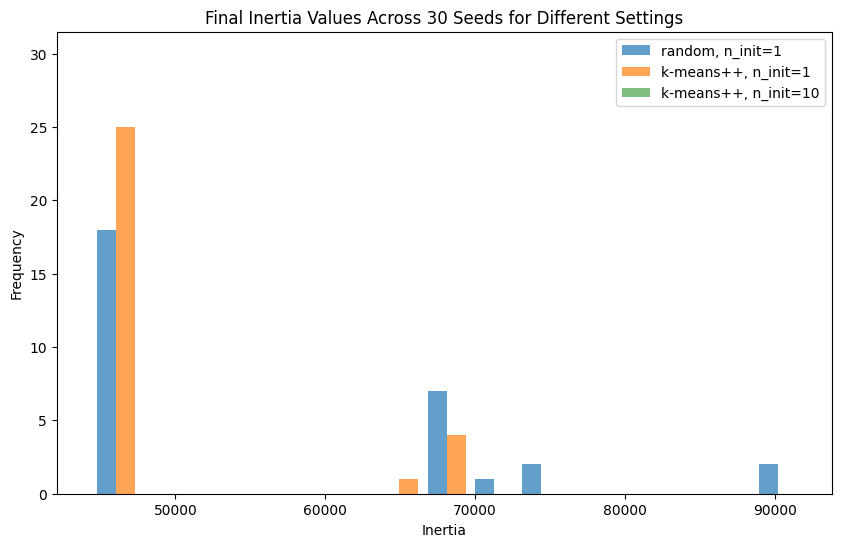

In [27]:
# YOUR CODE HERE
settings = [
    {"init": "random", "n_init": 1, "label": "random, n_init=1"},
    {"init": "k-means++", "n_init": 1, "label": "k-means++, n_init=1"},
    {"init": "k-means++", "n_init": 10, "label": "k-means++, n_init=10"},
]

results_summary = []
inertias_dict = {}

for s in settings:
  inertias = []
  for seed in range(30):
    kmeans = KMeans(
        n_clusters=5,
        init=s["init"],
        n_init=s["n_init"],
        random_state=seed,
        algorithm="lloyd",
    )
    kmeans.fit(X2)
    inertias.append(kmeans.inertia_)

  inertias = np.array(inertias)
  inertias_dict[s["label"]] = inertias

  best_inertia = inertias.min()
  pct_best = (np.isclose(inertias, best_inertia, atol=1e-2)).mean() * 100

  results_summary.append({
      "Setting": s["label"],
      "Distinct Inertias": len(np.unique(np.round(inertias, 1))),
      "Lowest": round(inertias.min(), 1),
      "Highest": round(inertias.max(), 1),
      "Pct Reached Best (%)": round(pct_best, 1),
  })

summary_df = pd.DataFrame(results_summary)
display(summary_df)

plt.figure(figsize=(10, 6))
plt.hist(
    [inertias_dict["random, n_init=1"], inertias_dict["k-means++, n_init=1"]],
    bins=15,
    label=["random, n_init=1", "k-means++, n_init=1"],
    alpha=0.7,
)
plt.hist(
    inertias_dict["k-means++, n_init=10"],
    bins=5,
    label=["k-means++, n_init=10"],
    alpha=0.5,
    color="green",
)
plt.title("Final Inertia Values Across 30 Seeds for Different Settings")
plt.xlabel("Inertia")
plt.ylabel("Frequency")
plt.legend()
plt.show()

### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


Best Run (Seed 0) Inertia: 44448.46
Worst Run (Seed 13) Inertia: 91761.98
Adjusted Rand Index (ARI) between best and worst: 0.4553


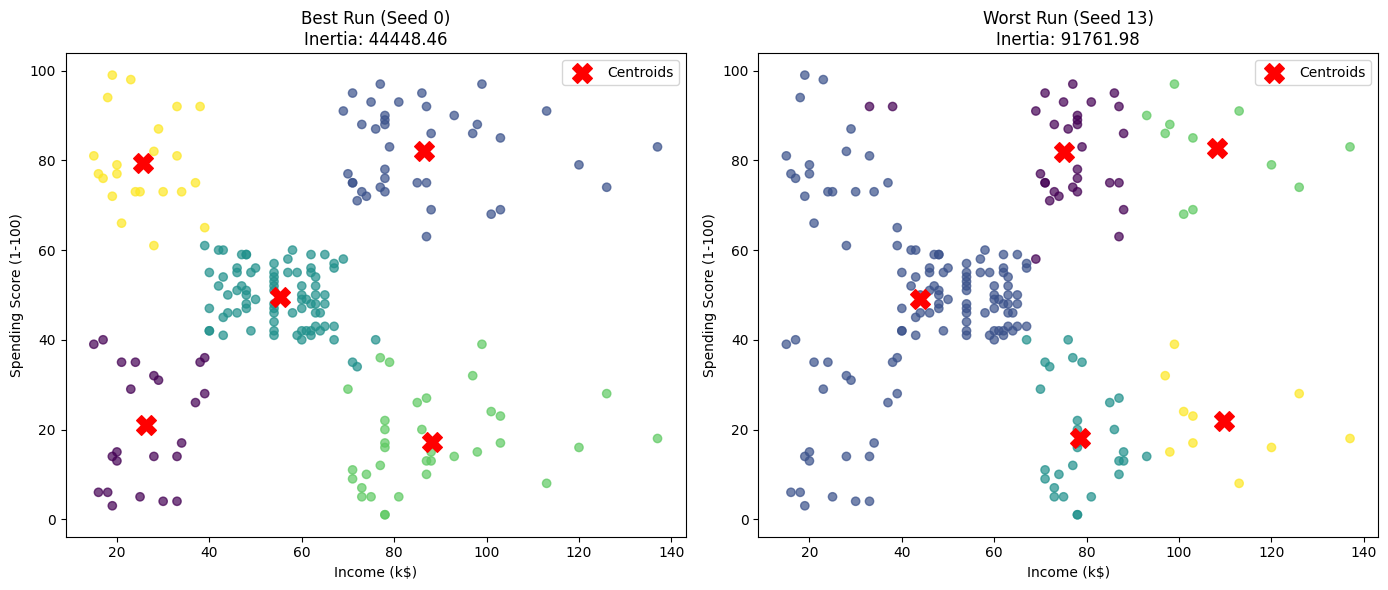

In [28]:
# YOUR CODE HERE
from sklearn.metrics import adjusted_rand_score

best_run = None
worst_run = None
best_inertia = float("inf")
worst_inertia = float("-inf")

for seed in range(30):
  kmeans = KMeans(
      n_clusters=5, init="random", n_init=1, random_state=seed, algorithm="lloyd"
  )
  labels = kmeans.fit_predict(X2)
  inertia = kmeans.inertia_

  if inertia < best_inertia:
    best_inertia = inertia
    best_run = {
        "seed": seed,
        "labels": labels,
        "centroids": kmeans.cluster_centers_,
        "inertia": inertia,
    }

  if inertia > worst_inertia:
    worst_inertia = inertia
    worst_run = {
        "seed": seed,
        "labels": labels,
        "centroids": kmeans.cluster_centers_,
        "inertia": inertia,
    }

ari = adjusted_rand_score(best_run["labels"], worst_run["labels"])

print(f"Best Run (Seed {best_run['seed']}) Inertia: {best_run['inertia']:.2f}")
print(
    f"Worst Run (Seed {worst_run['seed']}) Inertia: {worst_run['inertia']:.2f}"
)
print(f"Adjusted Rand Index (ARI) between best and worst: {ari:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(
    X2[:, 0], X2[:, 1], c=best_run["labels"], cmap="viridis", alpha=0.7
)
axes[0].scatter(
    best_run["centroids"][:, 0],
    best_run["centroids"][:, 1],
    color="red",
    marker="X",
    s=200,
    label="Centroids",
)
axes[0].set_title(
    f"Best Run (Seed {best_run['seed']})\nInertia: {best_run['inertia']:.2f}"
)
axes[0].set_xlabel("Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")
axes[0].legend()

axes[1].scatter(
    X2[:, 0], X2[:, 1], c=worst_run["labels"], cmap="viridis", alpha=0.7
)
axes[1].scatter(
    worst_run["centroids"][:, 0],
    worst_run["centroids"][:, 1],
    color="red",
    marker="X",
    s=200,
    label="Centroids",
)
axes[1].set_title(
    f"Worst Run (Seed {worst_run['seed']})\nInertia:"
    f" {worst_run['inertia']:.2f}"
)
axes[1].set_xlabel("Income (k$)")
axes[1].set_ylabel("Spending Score (1-100)")
axes[1].legend()

plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



**Your answers:**

(a)
- Random initialization (init='random', n_init=1) gave 14 different inertia values, and only 33.3% of runs found the best result (44,448.5).

- With k-means++ and n_init=1, there were 6 different values, and 60% of runs found the best result.

- With k-means++ and n_init=10, all runs found the same best result. This means it achieved 100% success.

(b)
The same data and K can give different results because K-Means depends on the initial positions of centroids. Different starting points can produce different clusters, and sometimes the algorithm gets stuck in a local minimum instead of finding the best result.

(c)
- k-means++ chooses better starting centroids by keeping them spread apart. This increases the chances of getting good clusters.

- n_init=10 runs K-Means 10 times with different starting points and selects the best result (lowest inertia). In our results, it achieved the best inertia (44,448.5) with 100% success.

(d)
We use ARI (Adjusted Rand Index) because cluster numbers can change between runs. For example, cluster 2 in one run may be cluster 4 in another run, even if both contain the same data points. ARI compares the actual grouping instead of cluster numbers.